In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [21]:
data = pd.read_csv('amazon.csv',encoding='iso-8859-1',parse_dates=['date'])

In [23]:
data.dtypes

year               int64
state                str
month                str
number           float64
date      datetime64[us]
dtype: object

In [24]:
# 1. Display Top 5 Rows of The Dataset
data.head()

,year,state,month,number,date
0,1998,Acre,Janeiro,0.0,1998-01-01
1,1999,Acre,Janeiro,0.0,1999-01-01
2,2000,Acre,Janeiro,0.0,2000-01-01
3,2001,Acre,Janeiro,0.0,2001-01-01
4,2002,Acre,Janeiro,0.0,2002-01-01


In [25]:
# 2. Check Last 5 Rows

data.tail()

,year,state,month,number,date
6449,2012,Tocantins,Dezembro,128.0,2012-01-01
6450,2013,Tocantins,Dezembro,85.0,2013-01-01
6451,2014,Tocantins,Dezembro,223.0,2014-01-01
6452,2015,Tocantins,Dezembro,373.0,2015-01-01
6453,2016,Tocantins,Dezembro,119.0,2016-01-01


In [28]:
# 3. Find Shape of Our Dataset (Number of Rows And Number of Columns)

data.shape

(6454, 5)

In [29]:
print ('Numbers of rows',data.shape[0])
print ('Numbers of Columns',data.shape[1])

Numbers of rows 6454
Numbers of Columns 5


In [31]:
# 4. Getting Information About Our Dataset Like Total Number Rows, Total Number of Columns, Datatypes of Each Column And Memory Requirement

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6454 entries, 0 to 6453
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   year    6454 non-null   int64         
 1   state   6454 non-null   str           
 2   month   6454 non-null   str           
 3   number  6454 non-null   float64       
 4   date    6454 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 252.2 KB


In [ ]:
# 5. Check For Duplicate Data and Drop Them


In [35]:
dup_data = data.duplicated().any()

In [36]:
print('Are there any duplicated values in the data',dup_data)

Are there any duplicated values in the data True


In [37]:
data = data.drop_duplicates()

In [39]:
data.shape




(6422, 5)

In [40]:
6454-6422

32

In [41]:
# 6. Check Null Values In The Dataset
data.isnull().sum

<bound method DataFrame.sum of        year  state  month  number   date
0     False  False  False   False  False
1     False  False  False   False  False
2     False  False  False   False  False
3     False  False  False   False  False
4     False  False  False   False  False
...     ...    ...    ...     ...    ...
6449  False  False  False   False  False
6450  False  False  False   False  False
6451  False  False  False   False  False
6452  False  False  False   False  False
6453  False  False  False   False  False

[6422 rows x 5 columns]>

In [48]:
# 7. Get Overall Statistics About The Dataframe

data.describe(include = 'all')

,year,state,month,number,date
count,6422.000000,6422,6422,6422.000000,6422
unique,NaN,23,12,NaN,NaN
top,NaN,Rio,Agosto,NaN,NaN
freq,NaN,697,540,NaN,NaN
mean,2007.490969,NaN,NaN,108.815178,2007-06-29 10:46:40.622859
min,1998.000000,NaN,NaN,0.000000,1998-01-01 00:00:00
25%,2003.000000,NaN,NaN,3.000000,2003-01-01 00:00:00
50%,2007.000000,NaN,NaN,24.497000,2007-01-01 00:00:00
75%,2012.000000,NaN,NaN,114.000000,2012-01-01 00:00:00
max,2017.000000,NaN,NaN,998.000000,2017-01-01 00:00:00


In [49]:
# 8. Rename Month Names To English


data.head()

,year,state,month,number,date
0,1998,Acre,Janeiro,0.0,1998-01-01
1,1999,Acre,Janeiro,0.0,1999-01-01
2,2000,Acre,Janeiro,0.0,2000-01-01
3,2001,Acre,Janeiro,0.0,2001-01-01
4,2002,Acre,Janeiro,0.0,2002-01-01


In [52]:
data['month_new']= data['month'].map({'Janeiro':'jan',
                                        'Fevereiro':'feb',
                                        'Março':'march',
                                        'Abril':'april',
                                        'Maio': 'may',
                                        'Junho':'jun',
                                        'Julho':'july',
                                        'Agosto':'august',
                                        'Setembro': 'sep',
                                        'Outubro':'oct',
                                        'Novembro':'nov',
                                        'Dezembro': 'dec'
                                       })

In [55]:
data.head()

,year,state,month,number,date,month_new
0,1998,Acre,Janeiro,0.0,1998-01-01,jan
1,1999,Acre,Janeiro,0.0,1999-01-01,jan
2,2000,Acre,Janeiro,0.0,2000-01-01,jan
3,2001,Acre,Janeiro,0.0,2001-01-01,jan
4,2002,Acre,Janeiro,0.0,2002-01-01,jan


In [6]:
# 9. Total Number of Fires Registered


In [57]:
data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [66]:
data1 = data.groupby('month_new')['number'].sum().reset_index()

In [ ]:
# 10. In Which Month Maximum Number of Forest Fires Were Reported?

<Axes: xlabel='month_new', ylabel='number'>

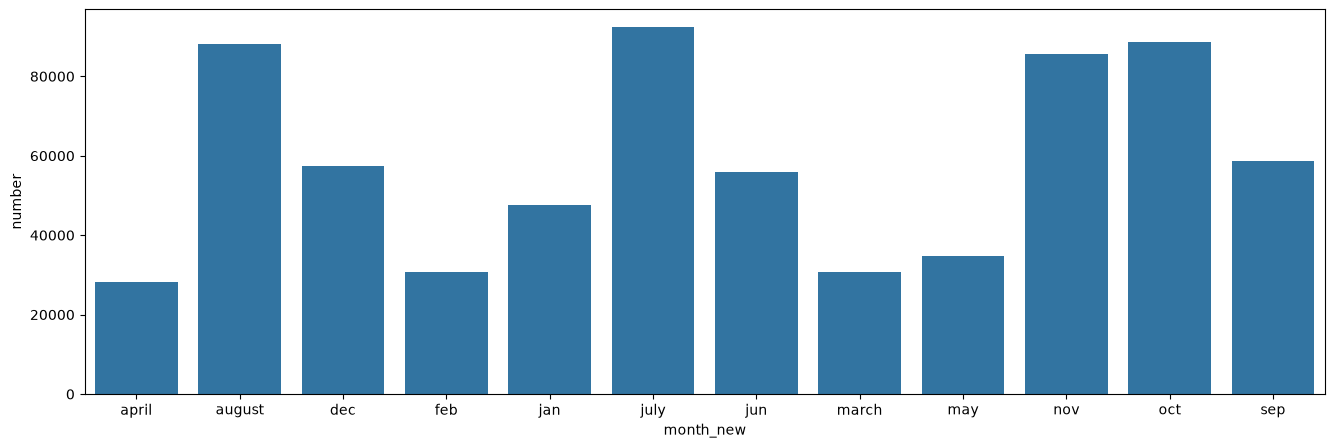

In [68]:
plt.figure(figsize=(16,5))
sns.barplot(x='month_new',y='number',data= data1)


In [ ]:
# 11. In Which Year Maximum Number of Forest Fires Was Reported?

<Axes: xlabel='year', ylabel='number'>

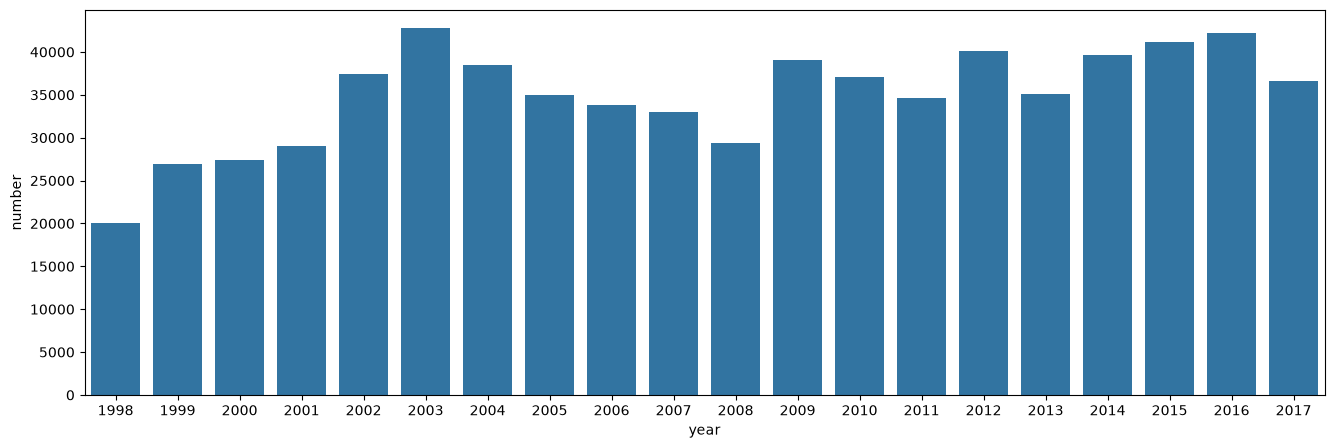

In [74]:
plt.figure(figsize=(16,5))
sns.barplot(x='year',y='number',data= data2)

In [8]:

data2 = data.groupby('year')['number'].sum().reset_index()
data2.head()

In [76]:
data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [77]:
# 12. In Which State Maximum Number of Forest Fires Was Reported?

data3 = data.groupby('state')['number'].sum().reset_index()
data3.head()

,state,number
0,Acre,18464.030
1,Alagoas,4606.000
2,Amapa,21831.576
3,Amazonas,30650.129
4,Bahia,44746.226


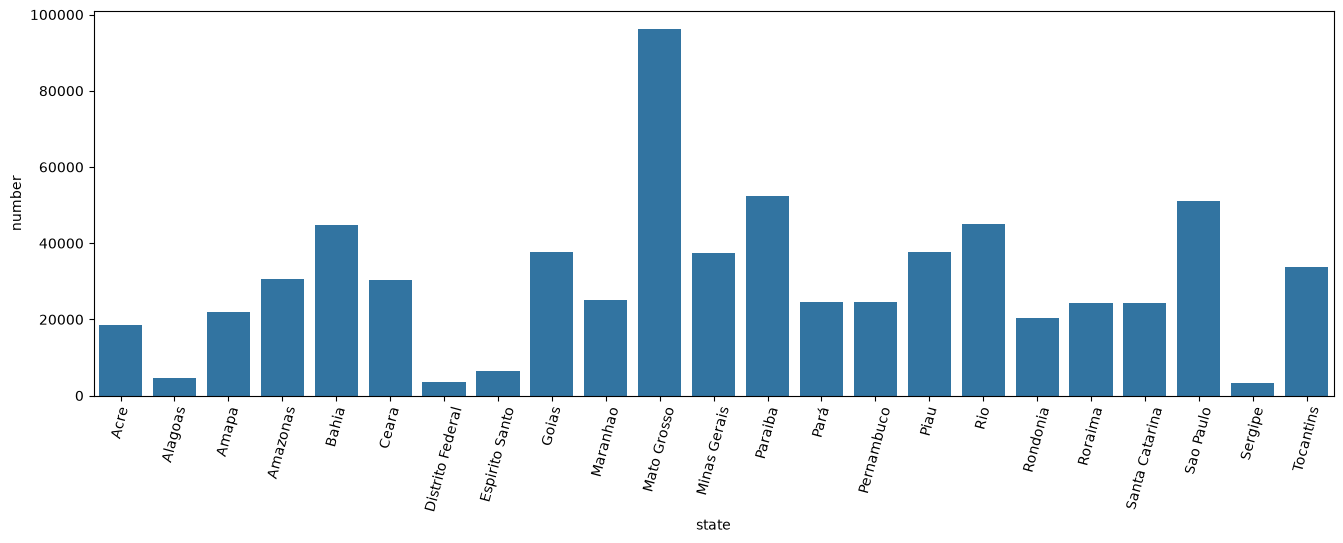

In [81]:
plt.figure(figsize=(16,5))
sns.barplot(x='state',y='number',data= data3)
plt.xticks(rotation=75)
plt.show()

In [82]:
# 13. Find Total Number of Fires Were Reported In Amazonas
data.columns


Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [86]:
data[data['state']=='Amazonas']['number'].sum()

np.float64(30650.129)

In [87]:
# 14. Display Number of Fires Were Reported In Amazonas (Year-Wise)

data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [96]:
data4 = data[data['state']=='Amazonas']
data5 = data4.groupby('year')['number'].sum().reset_index()
data5.head()


,year,number
0,1998,946.0
1,1999,1061.0
2,2000,853.0
3,2001,1297.0
4,2002,2852.0


<Axes: xlabel='year', ylabel='number'>

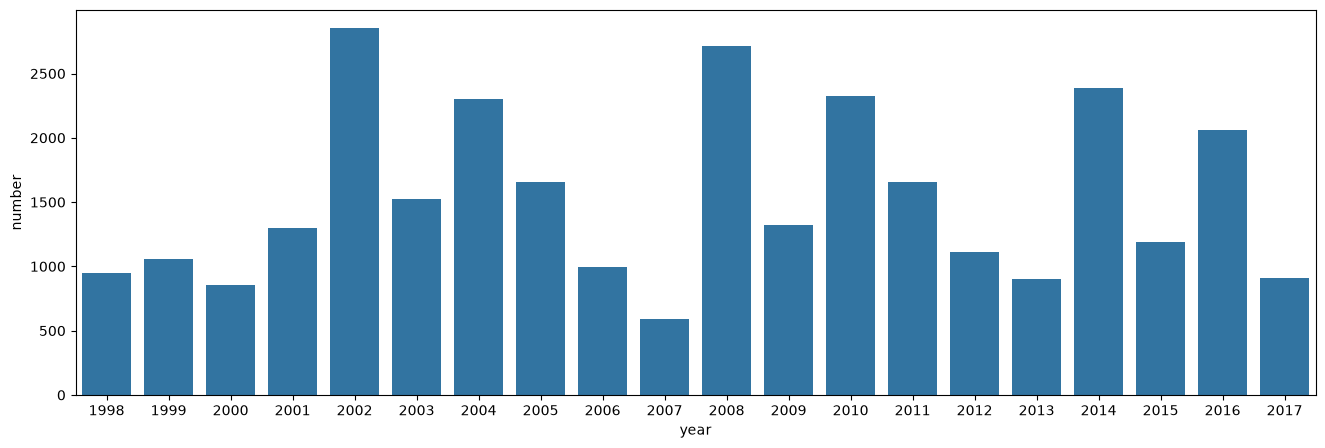

In [97]:
plt.figure(figsize=(16,5))
sns.barplot(x='year',y='number',data= data5)

In [98]:
# 15. Display Number of Fires Were Reported In Amazonas (Day-Wise)

data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [103]:
data6 = data[data['state']=='Amazonas']

In [114]:
import calendar

day= data6.groupby(data6['date'].dt.dayofweek)['number'].sum()

day.index = [calendar.day_name[i]for i in day.index]
day = day.reset_index()

<Axes: xlabel='index', ylabel='number'>

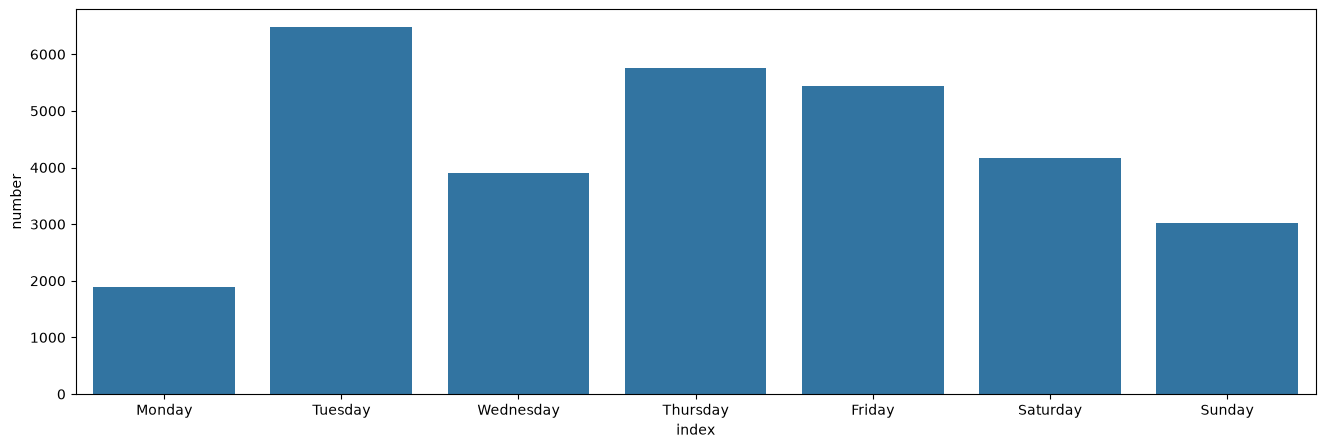

In [117]:
plt.figure(figsize=(16,5))

sns.barplot(x='index',y='number', data=day)

In [118]:
data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [127]:
# 16. Find Total Number of Fires  Were Reported In 2015 And Visualize Data Based on Each ‘Month’

fire = data[data['year']==2015].groupby('month_new')['number'].sum().reset_index()


<Axes: xlabel='month_new', ylabel='number'>

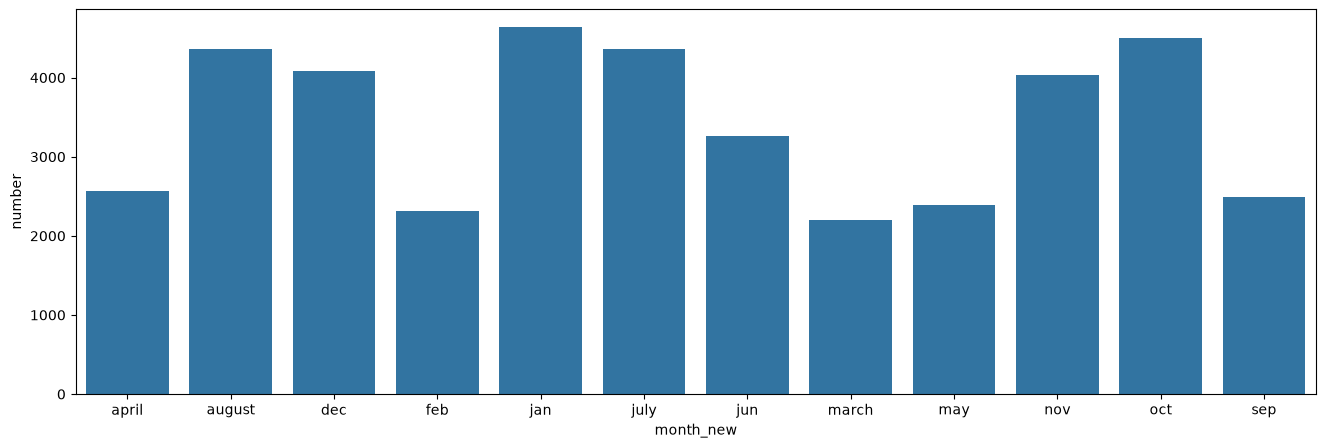

In [129]:
plt.figure(figsize=(16,5))

sns.barplot(x='month_new',y='number', data=fire)

In [130]:
data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [14]:

# 17. Find Average Number of Fires Were Reported From Highest to Lowest (State-Wise)



In [134]:
data8 = data.groupby('state')['number'].mean().sort_values(ascending=False).reset_index()

In [136]:
data8.head()

,state,number
0,Sao Paulo,213.896226
1,Mato Grosso,203.479975
2,Bahia,187.222703
3,Piau,158.174674
4,Goias,157.721841


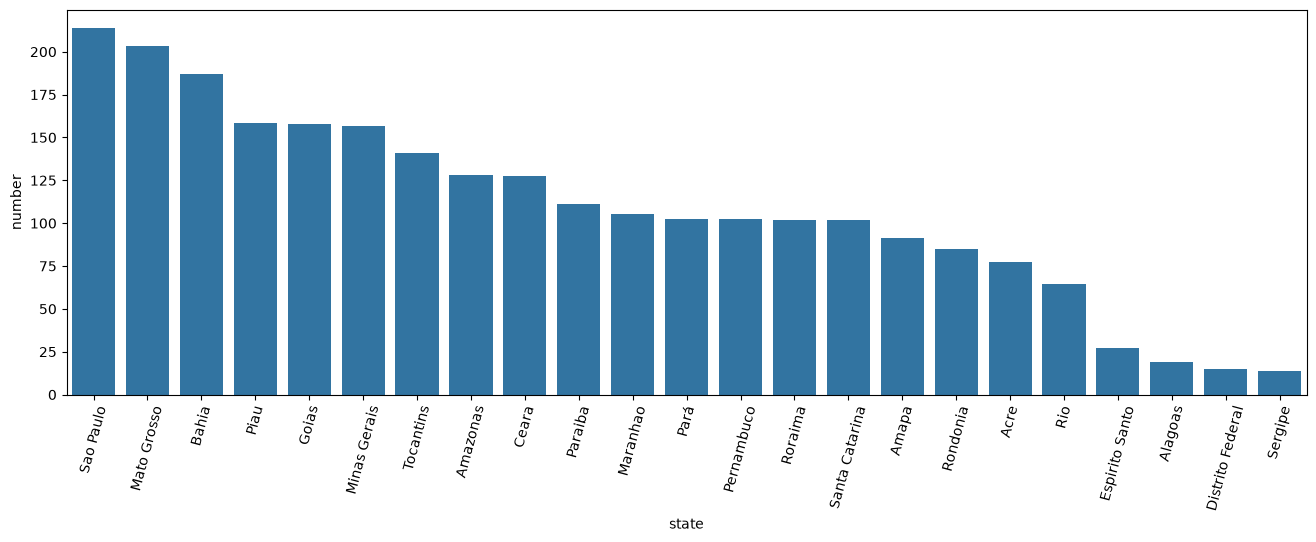

In [141]:
plt.figure(figsize=(16,5))

sns.barplot(x='state',y='number', data=data8)
plt.xticks(rotation=75)
plt.show()

In [ ]:
# 18.  To Find The State Names Where Fires Were Reported In 'dec' Month

In [142]:
data.columns

Index(['year', 'state', 'month', 'number', 'date', 'month_new'], dtype='str')

In [143]:
data[data['month_new'] == 'dec']['state'].unique()

<StringArray>
[            'Acre',          'Alagoas',            'Amapa',
         'Amazonas',            'Bahia',            'Ceara',
 'Distrito Federal',   'Espirito Santo',            'Goias',
         'Maranhao',      'Mato Grosso',     'Minas Gerais',
             'Pará',          'Paraiba',       'Pernambuco',
             'Piau',              'Rio',         'Rondonia',
          'Roraima',   'Santa Catarina',        'Sao Paulo',
          'Sergipe',        'Tocantins']
Length: 23, dtype: str